# Combiner diagnostics (Germany, development test years 2020-2023)

Weights over time and EWA's learning-rate grid. Built on `data/results/weights.parquet`, `metrics.csv`, `selections.csv` and `grid_scores.csv` (run `src/walk_forward.py` and `src/evaluate.py` first).

EWA's weights come from a separate run per fold: each starts uniform 3 years before its test year and runs through it. The dashed lines mark where one fold's run hands over to the next. BOA is one continuous run from 2017-01-01.

In [1]:
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

RESULTS_DIR = Path("..") / "data" / "results"
# The palette has 8 colour-blind-safe hues, so the two weakest experts share one grey band.
OTHER_BAND = "naive + arx"
OTHER_EXPERTS = ["naive", "arx"]
# The fixed order sets both the stacking order and each band's colour, identical in every chart.
EXPERT_ORDER = [OTHER_BAND, "lear_56", "lear_84", "lear_112", "lear_364", "lear_728", "lgbm", "rf", "knn"]
# Grey for the folded band, then the categorical palette checked for separation between neighbouring bands.
EXPERT_COLOURS = ["#9e9d96", "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
METHODS = ["ewa", "boa"]
METHOD_COLOURS = {"ewa": "#2a78d6", "boa": "#eb6834"}
FOLD_STARTS = [date(2021, 1, 1), date(2022, 1, 1), date(2023, 1, 1)]
TRAINING_YEARS = 3
HALF_LIVES = [7.0, 30.0, 365.0, float("inf")]
HALF_LIFE_LABELS = {7.0: "7 days", 30.0: "30 days", 365.0: "365 days", float("inf"): "no forgetting"}
# One blue ramp, light to dark, because half-life is ordered (short to long memory).
HALF_LIFE_COLOURS = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]

plt.rcParams["figure.figsize"] = (14, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
pl.Config.set_tbl_rows(40)

weights = pl.read_parquet(RESULTS_DIR / "weights.parquet")
metrics = pl.read_csv(RESULTS_DIR / "metrics.csv")
selections = pl.read_csv(RESULTS_DIR / "selections.csv")
selections.filter(pl.col("method") == "ewa").select("test_year", "eta", "half_life_days", "score")

test_year,eta,half_life_days,score
i64,f64,i64,f64
2020,1.0,7,0.401283
2021,1.0,7,0.407672
2022,1.0,7,0.444903
2023,1.0,7,0.481185


In [2]:
def weight_matrix(weights, method):
    """Return dates and a (days, bands) array of one method's daily weights, columns in EXPERT_ORDER."""
    banded = weights.filter(pl.col("method") == method).with_columns(
        pl.when(pl.col("expert").is_in(OTHER_EXPERTS)).then(pl.lit(OTHER_BAND)).otherwise(pl.col("expert")).alias("band")
    )
    banded = banded.group_by("date", "band").agg(pl.col("weight").sum())
    wide = banded.pivot(on="band", index="date", values="weight")
    wide = wide.sort("date")
    return wide["date"], wide.select(EXPERT_ORDER).to_numpy()


def mark_fold_starts(ax):
    """Draw a dashed line where each new fold's run begins."""
    for fold_start in FOLD_STARTS:
        ax.axvline(fold_start, color="black", linewidth=0.8, linestyle="--")


def plot_weight_stack(ax, dates, daily_weights, title):
    """Draw daily weights as a stacked area summing to 1, one band per expert."""
    ax.stackplot(
        dates,
        daily_weights.T,
        colors=EXPERT_COLOURS,
        labels=EXPERT_ORDER,
        edgecolor="white",
        linewidth=0.2,
    )
    mark_fold_starts(ax)
    ax.set_ylim(0, 1)
    ax.set_ylabel("weight")
    ax.set_title(title, loc="left")

## Daily weights

Bands are stacked bottom to top in the legend's order: naive at the bottom, LightGBM at the top.

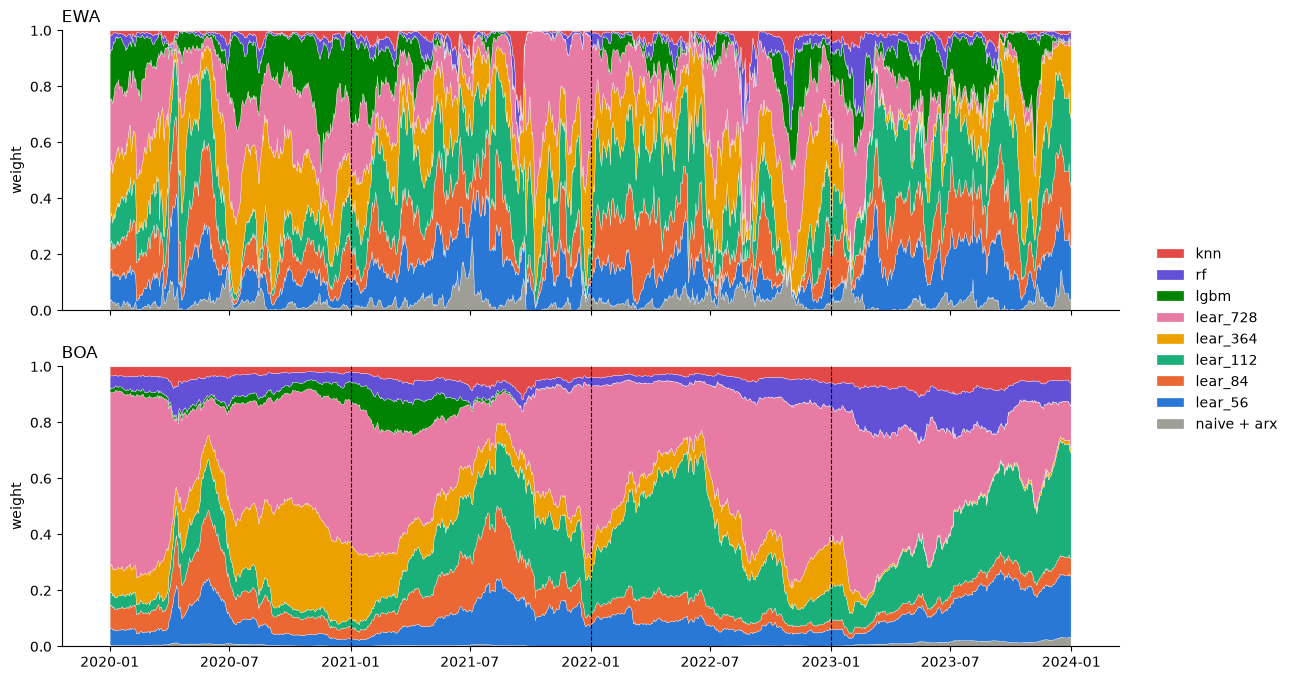

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for ax, method in zip(axes, METHODS):
    dates, daily_weights = weight_matrix(weights, method)
    plot_weight_stack(ax, dates, daily_weights, method.upper())
handles, labels = axes[0].get_legend_handles_labels()
# Reversed so the legend reads top to bottom in the same order as the bands.
fig.legend(handles[::-1], labels[::-1], loc="center right", frameon=False)
fig.subplots_adjust(right=0.88)
plt.show()

## How concentrated are the weights?

Effective number of experts = 1 / sum of squared weights: the number of experts (10) means equal weights (1/N), 1 means all weight on a single expert.

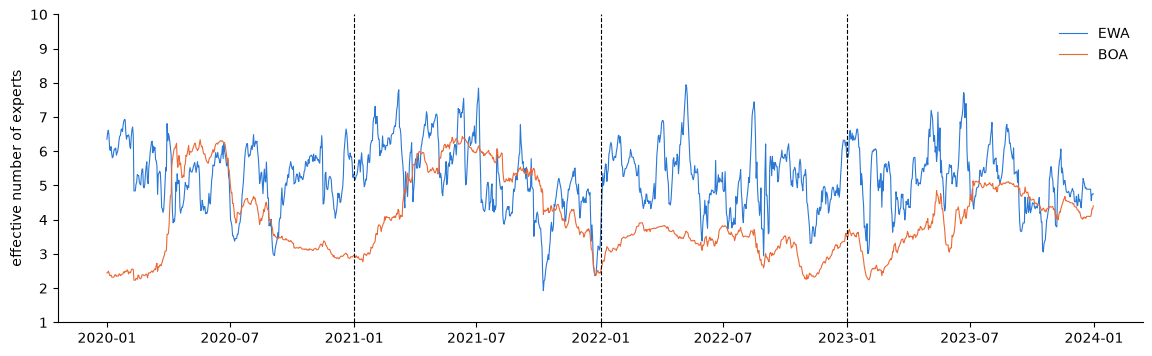

year,method,mean,min
i32,str,f64,f64
2020,"""boa""",3.876289,2.233188
2020,"""ewa""",5.268548,2.952868
2021,"""boa""",4.820831,2.379576
2021,"""ewa""",5.294192,1.928356
2022,"""boa""",3.301925,2.256956
2022,"""ewa""",5.18259,2.944805
2023,"""boa""",4.043037,2.244601
2023,"""ewa""",5.192155,3.011671


In [4]:
def effective_experts(weights):
    """Return one row per (date, method) with the effective number of experts."""
    concentration = weights.group_by("date", "method").agg((1 / (pl.col("weight") ** 2).sum()).alias("effective"))
    return concentration.sort("date")


concentration = effective_experts(weights)
fig, ax = plt.subplots()
for method in METHODS:
    series = concentration.filter(pl.col("method") == method)
    ax.plot(series["date"], series["effective"], linewidth=0.8, color=METHOD_COLOURS[method], label=method.upper())
mark_fold_starts(ax)
ax.set_ylim(1, weights["expert"].n_unique())
ax.set_ylabel("effective number of experts")
ax.legend(frameon=False)
plt.show()

concentration.group_by(pl.col("date").dt.year().alias("year"), "method").agg(
    pl.col("effective").mean().alias("mean"),
    pl.col("effective").min().alias("min"),
).sort("year", "method")

## Mean weight vs. how good each expert was that year

Each expert's mean weight per test year, next to its test-year MAE and its MAE rank among the experts (1 = best).

In [5]:
def mean_weights_by_year(weights):
    """Return one row per (year, expert) with each method's mean daily weight."""
    yearly = weights.group_by(pl.col("date").dt.year().alias("year"), "expert", "method").agg(pl.col("weight").mean())
    return yearly.pivot(on="method", index=["year", "expert"], values="weight")


def expert_mae_ranks(metrics):
    """Return one row per (year, expert) with the test-year MAE and its rank among the experts."""
    experts = metrics.filter(pl.col("method").str.starts_with("expert:"))
    experts = experts.with_columns(pl.col("method").str.replace("expert:", "").alias("expert"))
    ranked = experts.with_columns(pl.col("mae").rank("ordinal").over("year").cast(pl.Int32).alias("mae_rank"))
    return ranked.select("year", "expert", "mae", "mae_rank")


weight_vs_skill = mean_weights_by_year(weights).join(expert_mae_ranks(metrics), on=["year", "expert"])
weight_vs_skill.sort("year", "mae_rank").with_columns(pl.selectors.float().round(3))

year,expert,ewa,boa,mae,mae_rank
i32,str,f64,f64,f64,i32
2020,"""lear_364""",0.223,0.206,4.289,1
2020,"""lear_728""",0.214,0.425,4.29,2
2020,"""lgbm""",0.145,0.026,4.718,3
2020,"""lear_112""",0.129,0.066,4.779,4
2020,"""lear_84""",0.123,0.098,4.821,5
2020,"""lear_56""",0.101,0.079,5.04,6
2020,"""arx""",0.024,0.004,6.536,7
2020,"""rf""",0.021,0.062,6.659,8
2020,"""knn""",0.015,0.031,6.898,9


## EWA learning rate vs. training score

Selection score (mean scaled daily MAE over the 3 training years, outlier days excluded; lower is better) for every (eta, half-life) on the grid. The dashed grey line is eta = 0, which is 1/N. The circled point is the selected setting.

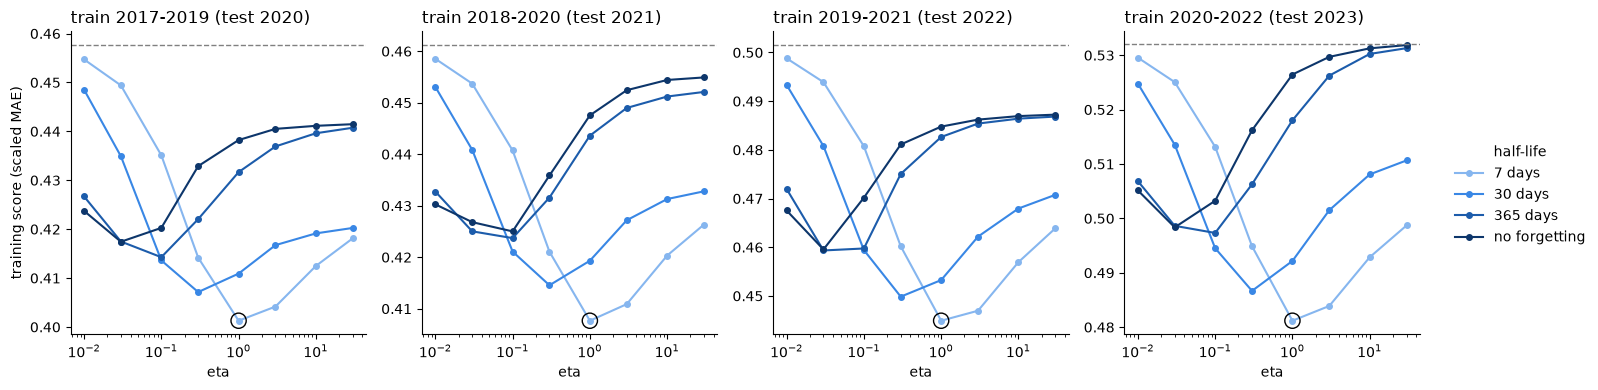

In [6]:
def plot_eta_scores(ax, fold_scores, test_year):
    """Draw training score vs. eta for one fold, one line per half-life, with 1/N as a reference."""
    equal_weight_score = fold_scores.filter(pl.col("eta") == 0)["score"][0]
    learning = fold_scores.filter(pl.col("eta") > 0)
    for half_life, colour in zip(HALF_LIVES, HALF_LIFE_COLOURS):
        line = learning.filter(pl.col("half_life_days") == half_life).sort("eta")
        ax.plot(line["eta"], line["score"], marker="o", markersize=4, linewidth=1.5, color=colour,
                label=HALF_LIFE_LABELS[half_life])
    best = fold_scores.sort("score").row(0, named=True)
    ax.scatter(best["eta"], best["score"], s=120, facecolors="none", edgecolors="black", zorder=3)
    ax.axhline(equal_weight_score, color="grey", linestyle="--", linewidth=1)
    ax.set_xscale("log")
    ax.set_xlabel("eta")
    ax.set_title(f"train {test_year - TRAINING_YEARS}-{test_year - 1} (test {test_year})", loc="left")


grid_scores = pl.read_csv(RESULTS_DIR / "grid_scores.csv").filter(pl.col("method") == "ewa")
test_years = grid_scores["test_year"].unique().sort().to_list()
fig, axes = plt.subplots(1, len(test_years), figsize=(16, 4))
for ax, test_year in zip(axes, test_years):
    plot_eta_scores(ax, grid_scores.filter(pl.col("test_year") == test_year), test_year)
axes[0].set_ylabel("training score (scaled MAE)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="half-life", loc="center right", frameon=False)
fig.tight_layout(rect=(0, 0, 0.9, 1))
plt.show()

The best eta shrinks as memory grows: the curves trace a ridge along which eta x (effective memory) stays roughly constant, and the short-memory end of that ridge scores best.

In [7]:
best_per_half_life = grid_scores.sort("score").group_by("test_year", "half_life_days", maintain_order=True).first()
best_per_half_life.pivot(on="test_year", index="half_life_days", values="eta").sort("half_life_days")

half_life_days,2020,2021,2022,2023
f64,f64,f64,f64,f64
7.0,1.0,1.0,1.0,1.0
30.0,0.3,0.3,0.3,0.3
365.0,0.1,0.1,0.03,0.1
inf,0.03,0.1,0.03,0.03
